# Olist E-Commerce Data Analytics

## Objective
Analyze e-commerce sales, customer behavior, product performance,
payments, delivery performance, and customer reviews.

## Workflow
1. Data loading and inspection
2. Data cleaning and validation
3. Exploratory data analysis
4. Data visualization
5. SQL analysis
6. Power BI and Streamlit dashboards

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


In [6]:
data_path = Path("data/raw")

customers = pd.read_csv(data_path / "olist_customers_dataset.csv")
order_items = pd.read_csv(data_path / "olist_order_items_dataset.csv")
payments = pd.read_csv(data_path / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(data_path / "olist_order_reviews_dataset.csv")
orders = pd.read_csv(data_path / "olist_orders_dataset.csv")
products = pd.read_csv(data_path / "olist_products_dataset.csv")
sellers = pd.read_csv(data_path / "olist_sellers_dataset.csv")
category_translation = pd.read_csv(
    data_path / "product_category_name_translation.csv"
)


In [7]:
datasets = {
    "customers": customers,
    "order_items": order_items,
    "payments": payments,
    "reviews": reviews,
    "orders": orders,
    "products": products,
    "sellers": sellers,
    "category_translation": category_translation,
}

summary = pd.DataFrame([
    {
        "dataset": name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "duplicate_rows": df.duplicated().sum(),
        "missing_cells": df.isna().sum().sum(),
    }
    for name, df in datasets.items()
])

summary

,dataset,rows,columns,duplicate_rows,missing_cells
0,customers,99441,5,0,0
1,order_items,112650,7,0,0
2,payments,103886,5,0,0
3,reviews,99224,7,0,145903
4,orders,99441,8,0,4908
5,products,32951,9,0,2448
6,sellers,3095,4,0,0
7,category_translation,71,2,0,0


In [9]:
print("Reviews missing values:")
print(reviews.isnull().sum())

print("\nOrders missing values:")
print(orders.isnull().sum())

print("\nProducts missing values:")
print(products.isnull().sum())

Reviews missing values:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Orders missing values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Products missing values:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


In [10]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [11]:
orders.groupby("order_status")[
    ["order_approved_at",
     "order_delivered_carrier_date",
     "order_delivered_customer_date"]
].apply(lambda x: x.isnull().sum())

,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


In [12]:
products["product_category_name"].isnull().sum()

np.int64(610)

In [13]:
products["product_category_name"].value_counts()

product_category_name
cama_mesa_banho                  3029
esporte_lazer                    2867
moveis_decoracao                 2657
beleza_saude                     2444
utilidades_domesticas            2335
                                 ... 
fashion_roupa_infanto_juvenil       5
casa_conforto_2                     5
pc_gamer                            3
seguros_e_servicos                  2
cds_dvds_musicais                   1
Name: count, Length: 73, dtype: int64

In [14]:
products["product_category_name"].isnull().sum()

np.int64(610)

In [15]:
products["product_category_name"] = products["product_category_name"].fillna("unknown")

In [16]:
products[products["product_weight_g"].isnull()]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,unknown,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
print(products[["product_weight_g", "product_length_cm",
                "product_height_cm", "product_width_cm"]].isnull().sum())

product_weight_g     2
product_length_cm    2
product_height_cm    2
product_width_cm     2
dtype: int64


In [18]:
print(reviews.isnull().sum())

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64


In [19]:
orders.dtypes

order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

In [20]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

In [21]:
orders[date_columns].dtypes

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

In [23]:
reviews["review_creation_date"] = pd.to_datetime(reviews["review_creation_date"])
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])

In [24]:
reviews[["review_creation_date", "review_answer_timestamp"]].dtypes

review_creation_date       datetime64[ns]
review_answer_timestamp    datetime64[ns]
dtype: object

In [25]:
payments.dtypes

order_id                 object
payment_sequential        int64
payment_type             object
payment_installments      int64
payment_value           float64
dtype: object

In [27]:
order_items["shipping_limit_date"] = pd.to_datetime(order_items["shipping_limit_date"])

In [28]:
order_items["shipping_limit_date"].dtype

dtype('<M8[ns]')

In [29]:
products.dtypes

product_id                     object
product_category_name          object
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64
dtype: object

In [30]:
print(customers.dtypes)
print(sellers.dtypes)

customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object
seller_id                 object
seller_zip_code_prefix     int64
seller_city               object
seller_state              object
dtype: object


In [32]:
print("Invalid review scores:")
print(reviews[~reviews["review_score"].between(1, 5)].shape[0])

print("Invalid order item prices:")
print((order_items["price"] < 0).sum())

print("Invalid freight values:")
print((order_items["freight_value"] < 0).sum())

Invalid review scores:
0
Invalid order item prices:
0
Invalid freight values:
0


In [33]:
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())
print("Duplicate customer IDs:", customers["customer_id"].duplicated().sum())
print("Duplicate product IDs:", products["product_id"].duplicated().sum())
print("Duplicate seller IDs:", sellers["seller_id"].duplicated().sum())

Duplicate order IDs: 0
Duplicate customer IDs: 0
Duplicate product IDs: 0
Duplicate seller IDs: 0


In [34]:
print("Orders without customers:",
      (~orders["customer_id"].isin(customers["customer_id"])).sum())

print("Order items without orders:",
      (~order_items["order_id"].isin(orders["order_id"])).sum())

print("Order items without products:",
      (~order_items["product_id"].isin(products["product_id"])).sum())

print("Order items without sellers:",
      (~order_items["seller_id"].isin(sellers["seller_id"])).sum())

Orders without customers: 0
Order items without orders: 0
Order items without products: 0
Order items without sellers: 0


In [36]:
from pathlib import Path

output_path = Path("data/processed")
output_path.mkdir(parents=True, exist_ok=True)

for name, df in datasets.items():
    df.to_csv(output_path / f"{name}.csv", index=False)



In [37]:
print("Total orders:", orders["order_id"].nunique())
print("Total customers:", customers["customer_unique_id"].nunique())
print("Total products:", products["product_id"].nunique())
print("Total sellers:", sellers["seller_id"].nunique())
print("Total revenue: R$", round(payments["payment_value"].sum(), 2))
print("Average order value: R$", round(
    payments.groupby("order_id")["payment_value"].sum().mean(), 2
))

Total orders: 99441
Total customers: 96096
Total products: 32951
Total sellers: 3095
Total revenue: R$ 16008872.12
Average order value: R$ 160.99


In [38]:
monthly_orders = orders.groupby(
    orders["order_purchase_timestamp"].dt.to_period("M")
)["order_id"].nunique()

monthly_revenue = payments.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id"
).groupby(
    orders["order_purchase_timestamp"].dt.to_period("M")
)["payment_value"].sum()

print("Monthly orders:")
print(monthly_orders)

print("\nMonthly revenue:")
print(monthly_revenue)

Monthly orders:
order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: order_id, dtype: int64

Monthly revenue:
order_purchase_timestamp
2016-09        656.56
2016-10      53039.30
2016-12         31.10
2017-01     127625.82
2017-02     268773.43
2017-03     411370.07
2017-04     363715.95
2017-05     573234.67
2017-06     495173.92
2017-07     619055.74
2017-08     677745.16
2017-09     646130.36
2017-10     731598.29
2017-11    1136803.92
2017-12     896301.79
2018-01    1115814.14
2018-02    1042551.33
2018-03    1114905.58
2018-04    1060435.35
2018-05    1055169.54
2018-06     947119.83
2018-07     9885

In [39]:
category_sales = order_items.merge(products, on="product_id")

print(
    category_sales.groupby("product_category_name")["price"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

product_category_name
beleza_saude              1258681.34
relogios_presentes        1205005.68
cama_mesa_banho           1036988.68
esporte_lazer              988048.97
informatica_acessorios     911954.32
moveis_decoracao           729762.49
cool_stuff                 635290.85
utilidades_domesticas      632248.66
automotivo                 592720.11
ferramentas_jardim         485256.46
Name: price, dtype: float64


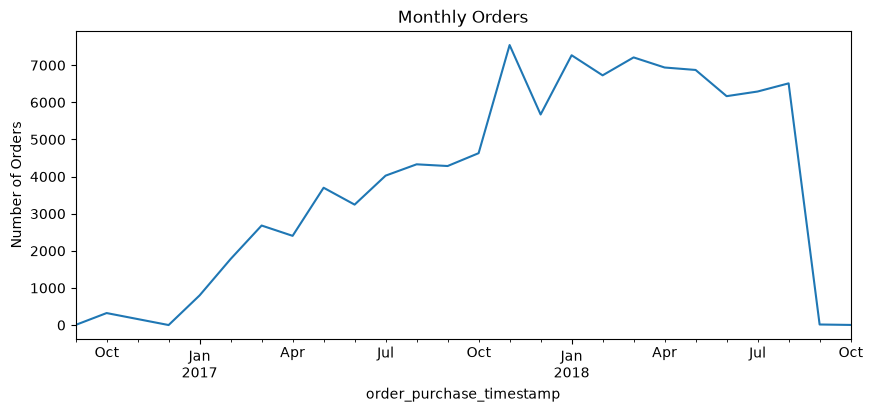

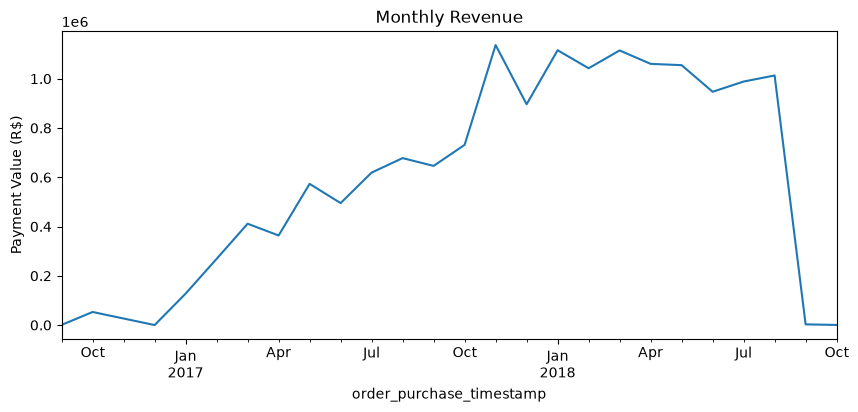

In [40]:
monthly_orders.plot(kind="line", figsize=(10, 4), title="Monthly Orders")
plt.ylabel("Number of Orders")
plt.show()

monthly_revenue.plot(kind="line", figsize=(10, 4), title="Monthly Revenue")
plt.ylabel("Payment Value (R$)")
plt.show()